# Network–Chip Production Balance → U.S. Computer Hardware Output

**Research-grade falsification notebook (retrospective macro pilot, NOT PIT / NOT equity alpha)** · 2026-10-28. The notebook is independently readable and executable from this study directory. It recomputes the baseline comparison and visual diagnostics; Monte Carlo CSVs are produced by `run_analysis.py` and checked here. Source data were inherited from a previous study, not independently recollected.

## 01. Abstract

**Question.** Does the two-month-stale communications-equipment-minus-semiconductor production growth gap predict U.S. computer/peripheral manufacturing output growth three months ahead, conditional on computer history, manufacturing and chip production? **Primary predeclared evaluation:** purged expanding-window OOS RMSE improvement over a fixed Ridge macro control. The latest-revised snapshot is not a historical PIT panel. Positive correlation or a small control-relative RMSE improvement would not alone establish investable equity alpha; negative results are admissible.

In [1]:
import matplotlib; matplotlib.use('module://matplotlib_inline.backend_inline')
import json, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display
from computer_factor import *
ROOT=Path.cwd()
assert (ROOT/'data/frozen_g17_electronics_2026-10-19.csv').is_file()
METRICS=json.loads((ROOT/'results/metrics.json').read_text())
print('Research date:',METRICS['research_date'],'| outcome:',METRICS['industry'])
print('PIT verified?',METRICS['source_vintage_pit_verified'],'| equity total returns?',METRICS['equity_total_returns_tested'])

Research date: 2026-10-28 | outcome: US computer and peripheral equipment manufacturing NAICS 3341
PIT verified? False | equity total returns? False


In [2]:
print('Primary result (control - factor RMSE):',round(METRICS['delta_rmse'],6),'log-pp')
print('OOS origins:',METRICS['oos_n'],'| outcome horizon:',METRICS['target_horizon_months'],'months')
print('Bootstrap 95% interval:',METRICS['bootstrap_ci_95_delta_rmse'])

Primary result (control - factor RMSE): -0.123681 log-pp
OOS origins: 117 | outcome horizon: 3 months
Bootstrap 95% interval: [-0.6418424169265807, 0.15201196858935986]


## 02. Research Design & Hypotheses

**H1:** the relative networking-production premium anticipates computer-hardware production. **H2:** adding this factor to controls improves OOS RMSE. **H3:** the effect survives 2020–2021 exclusion, alternative release buffers and horizon changes. **Null:** no incremental conditional predictive value. **Failure criteria:** the factor loses to controls or simple AR, uncertainty includes zero, or the result reverses outside a special regime. A network-vs-chip production gap is a *proxy*, not an observed order backlog or component shortage.

In [3]:
hypotheses=pd.DataFrame([['H1','factor positively predicts future computer YoY','descriptive association, not causal'],['H2','augmented Ridge beats same-origin control','primary OOS RMSE comparison'],['H3','sign stable across regimes and factor weights','regime, lag, horizon, perturbation']],columns=['hypothesis','prediction','test'])
display(hypotheses)

,hypothesis,prediction,test
0,H1,factor positively predicts future computer YoY,"descriptive association, not causal"
1,H2,augmented Ridge beats same-origin control,primary OOS RMSE comparison
2,H3,sign stable across regimes and factor weights,"regime, lag, horizon, perturbation"


In [4]:
print('No ex-post tuning: fixed Ridge alpha =',ALPHA,'| horizon =',HORIZON,'| release buffer =',RELEASE_BUFFER,'| min train =',MIN_TRAIN)

No ex-post tuning: fixed Ridge alpha = 20.0 | horizon = 3 | release buffer = 2 | min train = 48


## 03. Industry Context

Census NAICS 3341 covers computers, servers, storage devices and peripherals; 3342 covers communications equipment; 3344 covers semiconductors and other electronic components. This U.S. production classification is **not** global Dell/HP revenue. The G.17 fixed-snapshot computer production index rises from 77.1473 in 2011-01 to 182.6599 in 2026-09, but an index is **not** a dollar market-size estimate. Historical U.S. industry shipment dollars are **UNKNOWN** in this dataset. Source: Census 2017 NAICS definitions and Federal Reserve 2026-10-16 G.17.

In [5]:
raw=load_and_qa(ROOT/'data/frozen_g17_electronics_2026-10-19.csv')
print('Rows',len(raw),'dates',raw.date.min().date(),raw.date.max().date())
display(raw.head(4));display(raw.tail(4))

Rows 189 dates 2011-01-01 2026-09-01


,date,IPG3344S,IPG3341S,IPG3342S,IPMAN
0,2011-01-01,53.7716,77.1473,72.3429,94.4812
1,2011-02-01,54.1177,75.5871,73.4670,94.6810
2,2011-03-01,53.7497,75.0478,73.5593,95.3244
3,2011-04-01,53.7194,75.4652,73.1306,94.7934


,date,IPG3344S,IPG3341S,IPG3342S,IPMAN
185,2026-06-01,188.2611,180.3074,230.2037,99.2705
186,2026-07-01,192.2137,182.4972,231.3716,99.4308
187,2026-08-01,194.5212,184.0602,233.0737,99.1776
188,2026-09-01,198.6335,182.6599,233.9331,99.4361


In [6]:
first,last=raw.IPG3341S.iloc[[0,-1]]
annualized=(last/first)**(12/(len(raw)-1))-1
print(f'Computer output index: {first:.4f} → {last:.4f}; annualized index growth {100*annualized:.3f}% (NOT dollar market size)')

Computer output index: 77.1473 → 182.6599; annualized index growth 5.656% (NOT dollar market size)


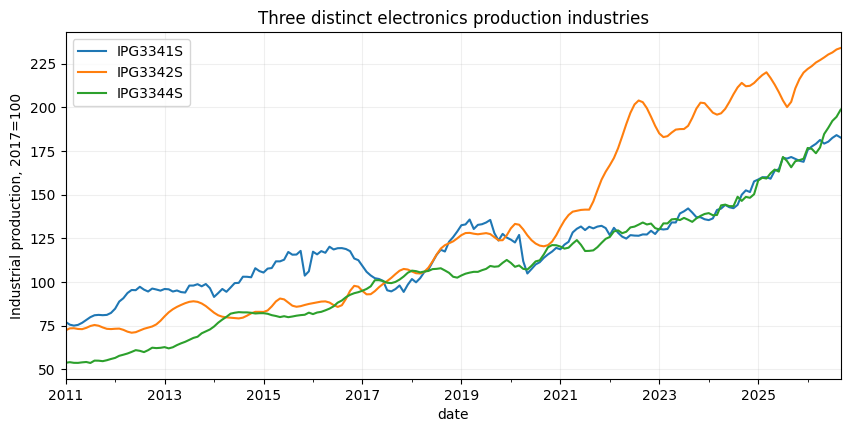

In [7]:
fig,ax=plt.subplots(figsize=(10,4.5))
raw.set_index('date')[['IPG3341S','IPG3342S','IPG3344S']].plot(ax=ax)
ax.set(title='Three distinct electronics production industries',ylabel='Industrial production, 2017=100');ax.grid(alpha=.2);plt.show()

## 04. Data & Source Integrity

**Source register:** A = official Fed/Census/SEC sources; B = inherited byte-identical repository snapshot; C = analyst-created economic mechanism. The original data were copied from `Semiconductor-Device-Gap-to-Alpha-U.S.-Chip-Manufacturing/data/fred_g17_snapshot_2011_2026.csv` with verified Git blob SHA `3d111120b93de0a5eb153d794772225f5dd1a6c4`. Independent full-series re-download and historical first-release comparisons have **not** been completed. The inherited data are 189 contiguous months with four strictly positive index series.

In [8]:
register=pd.read_csv(ROOT/'data/source_register.csv');print('A/B/C source rows:',register.grade.value_counts().to_dict());display(register[['source_id','grade','publisher','publication_date','original_url']])

A/B/C source rows: {'A': 9, 'B': 1, 'C': 1}


,source_id,grade,publisher,publication_date,original_url
0,FED_G17,A,Federal Reserve Board,2026-10-16,https://www.federalreserve.gov/releases/g17/20...
1,IPG3341S,A,Federal Reserve via FRED,2026-10-16,https://fred.stlouisfed.org/series/IPG3341S
2,IPG3342S,A,Federal Reserve via FRED,2026-10-16,https://fred.stlouisfed.org/series/IPG3342S
3,IPG3344S,A,Federal Reserve via FRED,2026-10-16,https://fred.stlouisfed.org/series/IPG3344S
4,IPMAN,A,Federal Reserve via FRED,2026-10-16,https://fred.stlouisfed.org/series/IPMAN
5,SOURCE_COPY,B,Signals-to-Alpha repository,2026-10-19,https://github.com/HyeonbinJung/Signals-to-Alp...
6,NAICS_3341,A,U.S. Census Bureau,2017,https://www.census.gov/naics/2017NAICS/2017_De...
7,DELL_2025,A,Dell Technologies SEC 10-K,2025-03-25,https://www.sec.gov/Archives/edgar/data/157199...
8,HPQ_2025,A,HP Inc. SEC 10-K,2025-12-10,https://www.sec.gov/Archives/edgar/data/47217/...
9,CISCO_2025,A,Cisco Systems,2025,https://www.cisco.com/c/en/us/about/annual-rep...


In [9]:
assert len(raw)==189 and raw.date.is_unique
assert raw[RAW].notna().all().all() and (raw[RAW]>0).all().all()
assert raw.date.dt.to_period('M').astype(int).diff().dropna().eq(1).all()
sha=hashlib.sha256((ROOT/'data/frozen_g17_electronics_2026-10-19.csv').read_bytes()).hexdigest()
assert sha=='6a6fca4b29755f0c2cae8ccfae1016a22648e724787cc42e726ac945583c351c'
print('PASS source continuity / no missing / positive / frozen SHA-256',sha)

PASS source continuity / no missing / positive / frozen SHA-256 6a6fca4b29755f0c2cae8ccfae1016a22648e724787cc42e726ac945583c351c


In [10]:
raw[RAW].describe().T[['count','min','50%','max']]

,count,min,50%,max
IPG3341S,189.0,75.0478,117.8093,184.0602
IPG3342S,189.0,70.9743,121.0720,233.9331
IPG3344S,189.0,53.6659,106.2109,198.6335
IPMAN,189.0,79.8587,98.7947,102.0449


## 05. Point-in-Time Availability

Formation month `t` can use no later than observation `t−2`; this buffer is deliberately conservative for the ordinary monthly release cycle, but **2026-revised values were not actually available in the past**. Training label purge is `u+h ≤ t−2`. No first-release vintages or exact historic publication timestamps were collected. We explicitly label the study **retrospective fixed-snapshot**. The `target_month` is always later than the formation date; all input observations are earlier.

In [11]:
panel=make_panel(raw,h=3,buffer=2)
cols=['date','latest_input_month','target_month','computer_stale','network_stale','chip_stale','factor','target']
display(panel[cols].iloc[18:23])

,date,latest_input_month,target_month,computer_stale,network_stale,chip_stale,factor,target
18,2012-07-01,2012-05-01,2012-10-01,21.905292,-2.845114,10.494133,-13.339247,17.240491
19,2012-08-01,2012-06-01,2012-11-01,19.684363,-3.398094,11.771070,-15.169165,16.462599
20,2012-09-01,2012-07-01,2012-12-01,19.669729,-3.534804,12.170025,-15.704829,14.386730
21,2012-10-01,2012-08-01,2013-01-01,16.640153,-2.940892,8.470588,-11.411479,12.500358
22,2012-11-01,2012-09-01,2013-02-01,15.254532,-1.461678,10.379848,-11.841527,7.591487


In [12]:
valid=panel.dropna(subset=['factor','target']);assert (valid.latest_input_month<valid.date).all();assert (valid.target_month>valid.date).all()
print('Candidate fully labeled factor/target observations:',len(valid),'| strict input and target month inequalities PASS')

Candidate fully labeled factor/target observations: 172 | strict input and target month inequalities PASS


## 06. Factor Construction

Define `g(s,m)=100 ln(IP(s,m)/IP(s,m−12))` in log percentage points. The factor is `F(t)=g(NAICS3342,t−2)−g(NAICS3344,t−2)` and the outcome is `Y(t,3)=g(NAICS3341,t+3)`. The target is a **future YoY level**, not a three-month change. Computer persistence is `g(3341,t−2)`; momentum is its difference from `t−5`. All factor coefficients are fixed ex ante. No full-sample z-score, no ex-post sector-weight optimization.

In [13]:
row=panel.iloc[60];print('Factor algebra check:',row.factor,'=',row.network_stale,'-',row.chip_stale)
assert np.isclose(row.factor,row.network_stale-row.chip_stale)
assert np.isclose(row.target,panel.iloc[63].computer_yoy)

Factor algebra check: 5.546125491477466 = 4.648191528959775 - -0.8979339625176906


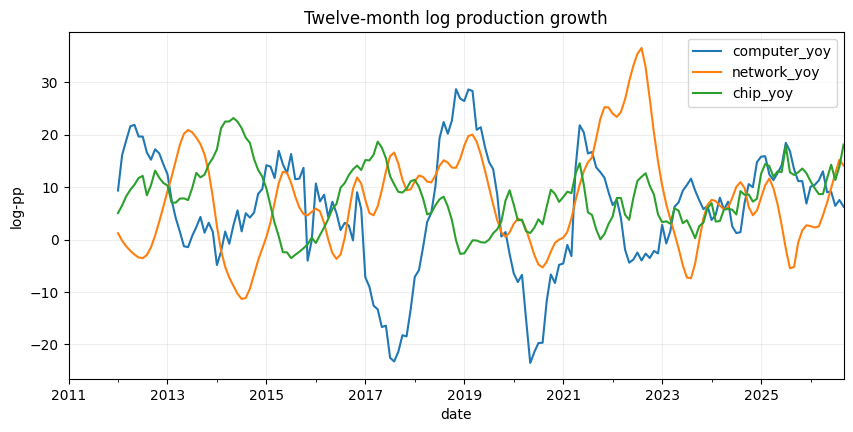

In [14]:
fig,ax=plt.subplots(figsize=(10,4.5));panel.set_index('date')[['computer_yoy','network_yoy','chip_yoy']].plot(ax=ax)
ax.set(title='Twelve-month log production growth',ylabel='log-pp');ax.grid(alpha=.2);plt.show()

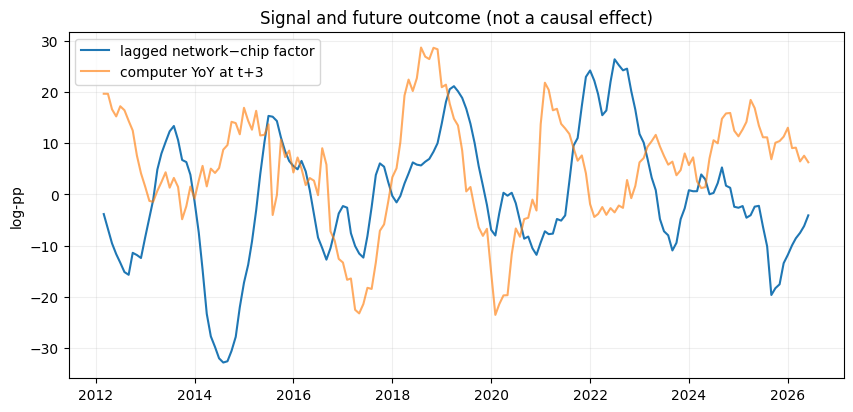

In [15]:
fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(valid.date,valid.factor,label='lagged network−chip factor');ax.plot(valid.date,valid.target,label='computer YoY at t+3',alpha=.65);ax.legend();ax.set(title='Signal and future outcome (not a causal effect)',ylabel='log-pp');ax.grid(alpha=.2);plt.show()

## 07. Exposure & Transmission

The *measured* exposures are industry series: 3342 network production (+1), 3344 semiconductor/electronics production (−1), and 3341 computer hardware (outcome). Dell, HP and Cisco appear **only** as dated filing-based examples of overlapping products. Their U.S. NAICS revenue weights and historical filing-date-adjusted segment panels are **UNKNOWN**, so company-level leave-one-out, issuer IC and returns spreads are **not applicable**. Industry-level factor-weight perturbations are tested instead.

In [16]:
expmap=pd.read_csv(ROOT/'data/exposure_map.csv');display(expmap[['entity','entity_type','naics_or_ticker','role','evidence_date','historical_weight','usable_for_backtest']])

,entity,entity_type,naics_or_ticker,role,evidence_date,historical_weight,usable_for_backtest
0,Computer and peripheral equipment,industry,3341,independent outcome,2017,NaN,yes as aggregate series
1,Communications equipment,industry,3342,network proxy,2017,1.0 factor coefficient,yes as aggregate series
2,Semiconductors and electronic components,industry,3344,chip proxy,2017,-1.0 factor coefficient,yes as aggregate series
3,Dell Technologies,issuer,DELL,descriptive downstream issuer,2025-03-25,UNKNOWN,no
4,HP Inc.,issuer,HPQ,descriptive downstream issuer,2025-12-10,UNKNOWN,no
5,Cisco Systems,issuer,CSCO,descriptive upstream/demand issuer,2025,UNKNOWN,no


In [17]:
print('Measured macro industry rows:',int((expmap.entity_type=='industry').sum()),'| issuer rows descriptive only:',int((expmap.entity_type=='issuer').sum()))
assert (expmap.loc[expmap.entity_type=='issuer','usable_for_backtest']=='no').all()

Measured macro industry rows: 3 | issuer rows descriptive only: 3


## 08. Outcomes & Baselines

Every model is evaluated on identical formation dates. Training is **expanding-window** with ≥48 fully labeled origins, fixed Ridge `alpha=20` and per-origin train-only standardization. Same-origin comparators: historical mean, stale YoY persistence, momentum extrapolation, AR Ridge, multivariate macro Ridge, factor-only Ridge, and macro-plus-factor Ridge. For each t, training u is admitted only when u+3≤t−2; overlapping future labels are purged. There are no independent corporate fundamentals or stock returns in the panel.

In [18]:
o=oos(panel);print('Purged OOS origins:',len(o),'from',o.date.min().date(),'to',o.date.max().date());display(o.head(5))

Purged OOS origins: 117 from 2016-10-01 to 2026-06-01


,date,target_month,latest_input_month,origin_index,n_train,y,historical_mean,persistence,momentum,ar_ridge,macro_control,network_factor_only,full_network_balance
0,2016-10-01,2017-01-01,2016-08-01,69,48,-7.209025,6.612532,3.207055,1.198341,5.000391,3.906560,7.230718,4.953050
1,2016-11-01,2017-02-01,2016-09-01,70,49,-9.023332,6.532505,2.691213,1.509029,5.030651,4.218921,6.773574,4.410522
2,2016-12-01,2017-03-01,2016-10-01,71,50,-12.594292,6.398973,-0.144065,-1.128594,4.279554,3.641624,6.228772,3.142589
3,2017-01-01,2017-04-01,2016-11-01,72,51,-13.303769,6.450774,9.040799,11.957671,7.499557,6.560030,6.096644,5.312012
4,2017-02-01,2017-05-01,2016-12-01,73,52,-16.680346,6.438924,5.834575,7.406256,6.436602,5.891830,6.105834,4.840540


In [19]:
assert len(o)==117 and (o.n_train>=48).all()
assert (o.latest_input_month<o.date).all() and (o.target_month>o.date).all()
assert o[['historical_mean','persistence','momentum','ar_ridge','macro_control','network_factor_only','full_network_balance']].notna().all().all()
print('PASS same-date forecast alignment and target-release purge')

PASS same-date forecast alignment and target-release purge


In [20]:
s=scorecard(o);display(s[['model','n','rmse_log_pp','mae_log_pp']].sort_values('rmse_log_pp'))

,model,n,rmse_log_pp,mae_log_pp
3,ar_ridge,117,9.898829,7.844379
2,momentum,117,11.061537,9.067156
4,macro_control,117,11.347870,8.446738
6,full_network_balance,117,11.471551,8.718604
1,persistence,117,11.722942,9.496989
0,historical_mean,117,13.148217,10.626410
5,network_factor_only,117,13.419351,10.876690


## 09. Empirical Findings

The augmented model has RMSE **11.4716**, worse than macro controls **11.3479** and AR Ridge **9.8988**. The RMSE improvement is **−0.1237 log-pp** and MAE deteriorates from **8.4467** to **8.7186**. Thus the proposed conditional factor **fails H2**; no security-level result can be inferred. These are saved computed numbers, not projected estimates.

In [21]:
gain=subset_gain(o);print('RMSE improvement (control−full):',round(gain,6));print('MAE control/full:',mae(o.y,o.macro_control),mae(o.y,o.full_network_balance));assert gain<0

RMSE improvement (control−full): -0.123681
MAE control/full: 8.446737900580327 8.718604251499658


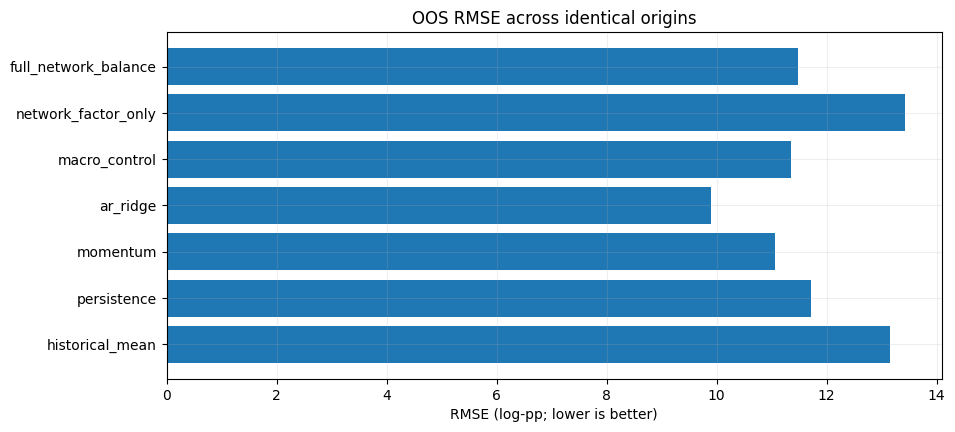

In [22]:
fig,ax=plt.subplots(figsize=(10,4.5));ax.barh(s.model,s.rmse_log_pp);ax.set(title='OOS RMSE across identical origins',xlabel='RMSE (log-pp; lower is better)');ax.grid(alpha=.2);plt.show()

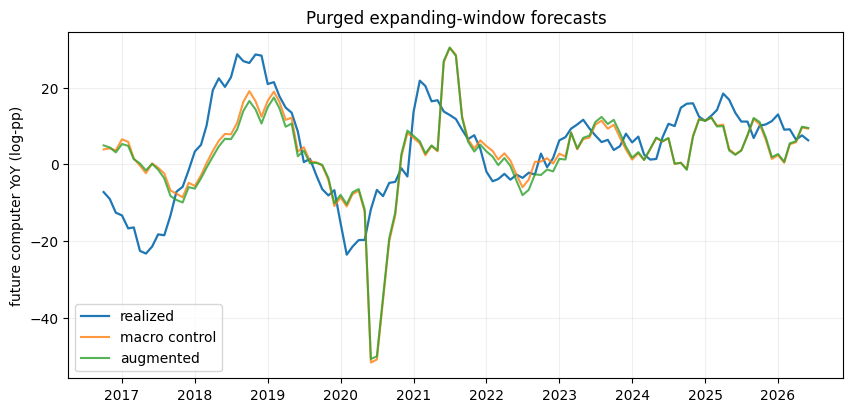

In [23]:
fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(o.date,o.y,label='realized',lw=1.6);ax.plot(o.date,o.macro_control,label='macro control',alpha=.8);ax.plot(o.date,o.full_network_balance,label='augmented',alpha=.8);ax.legend();ax.set(title='Purged expanding-window forecasts',ylabel='future computer YoY (log-pp)');ax.grid(alpha=.2);plt.show()

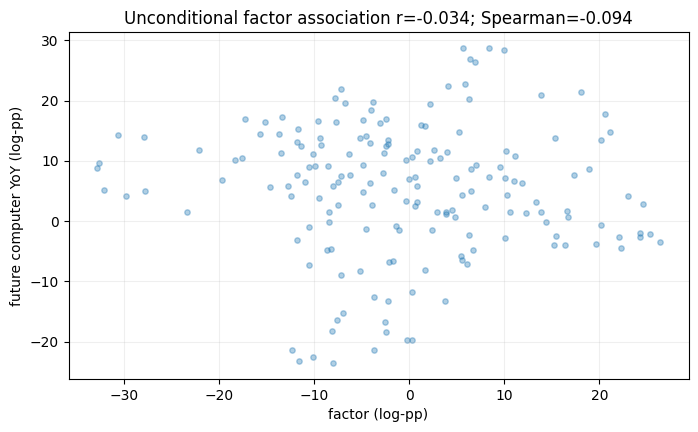

In [24]:
fig,ax=plt.subplots(figsize=(8,4.5));ax.scatter(valid.factor,valid.target,s=15,alpha=.35);corr=valid.factor.corr(valid.target);rho=spearmanr(valid.factor,valid.target).statistic;ax.set(title=f'Unconditional factor association r={corr:.3f}; Spearman={rho:.3f}',xlabel='factor (log-pp)',ylabel='future computer YoY (log-pp)');ax.grid(alpha=.2);plt.show()

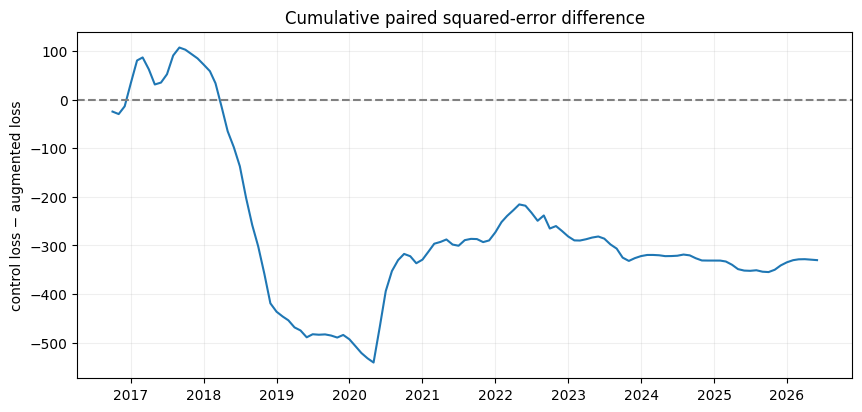

In [25]:
paired=(o.y-o.macro_control)**2-(o.y-o.full_network_balance)**2
fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(o.date,paired.cumsum());ax.axhline(0,color='gray',ls='--');ax.set(title='Cumulative paired squared-error difference',ylabel='control loss − augmented loss');ax.grid(alpha=.2);plt.show()

## 10. Robustness & Placebos

**Block-aware diagnostic:** 1,000 refits of a factor with 12-month contiguous blocks reordered (controls and labels unchanged). The upper-tail fraction is exploratory, **not an exact p-value** because time-series blocks may be non-exchangeable. **Uncertainty:** 2,000 paired 12-month moving-block bootstrap draws from the common OOS errors. **Exposure sensitivity:** 1,000 refits of `network − k×chip`, `k∈[0.5,1.5]`. No company leave-one-out can be performed without company data; a leave-one-year-out *evaluation* is reported instead.

In [26]:
null=pd.read_csv(ROOT/'results/block_placebo_1000.csv');tail=(1+(null.null_delta_rmse_log_pp>=gain).sum())/(len(null)+1)
print('1000 block-reordered refits; exploratory upper-tail fraction:',round(tail,6));assert len(null)==1000

1000 block-reordered refits; exploratory upper-tail fraction: 0.40959


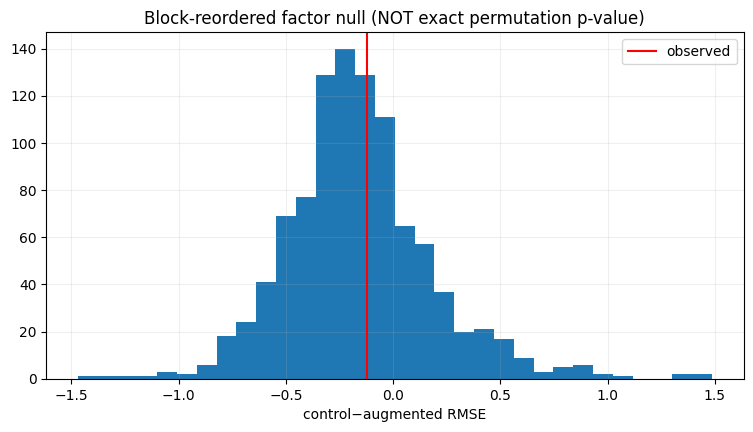

In [27]:
fig,ax=plt.subplots(figsize=(9,4.5));ax.hist(null.null_delta_rmse_log_pp,bins=32);ax.axvline(gain,color='red',label='observed');ax.legend();ax.set(title='Block-reordered factor null (NOT exact permutation p-value)',xlabel='control−augmented RMSE');ax.grid(alpha=.2);plt.show()

In [28]:
boot=pd.read_csv(ROOT/'results/paired_block_bootstrap_2000.csv');ci=np.quantile(boot.delta_rmse_log_pp,[.025,.975]);print('2000 moving-block paired draws, 95% interval:',ci,'crosses zero?',ci[0]<=0<=ci[1]);assert len(boot)==2000

2000 moving-block paired draws, 95% interval: [-0.64184242  0.15201197] crosses zero? True


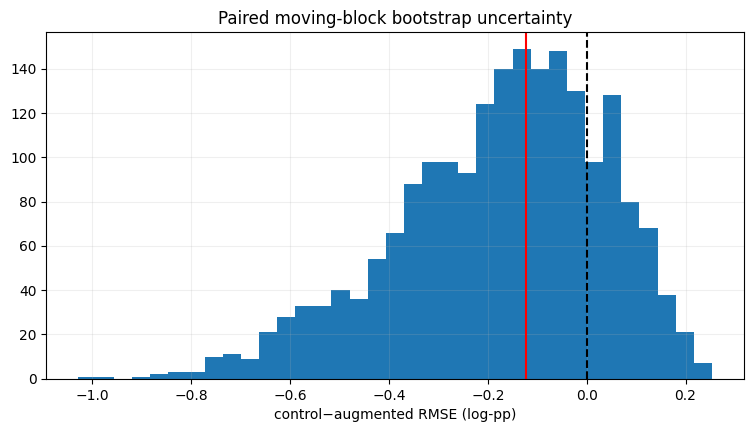

In [29]:
fig,ax=plt.subplots(figsize=(9,4.5));ax.hist(boot.delta_rmse_log_pp,bins=35);ax.axvline(0,color='black',ls='--');ax.axvline(gain,color='red');ax.set(title='Paired moving-block bootstrap uncertainty',xlabel='control−augmented RMSE (log-pp)');ax.grid(alpha=.2);plt.show()

In [30]:
weights=pd.read_csv(ROOT/'results/exposure_perturbation_1000.csv');display(weights.delta_rmse_log_pp.describe());print('Positive improvement fraction:',(weights.delta_rmse_log_pp>0).mean());assert len(weights)==1000

count    1000.000000
mean       -0.125054
std         0.019555
min        -0.165545
25%        -0.140453
50%        -0.121214
75%        -0.108602
max        -0.097117
Name: delta_rmse_log_pp, dtype: float64

Positive improvement fraction: 0.0


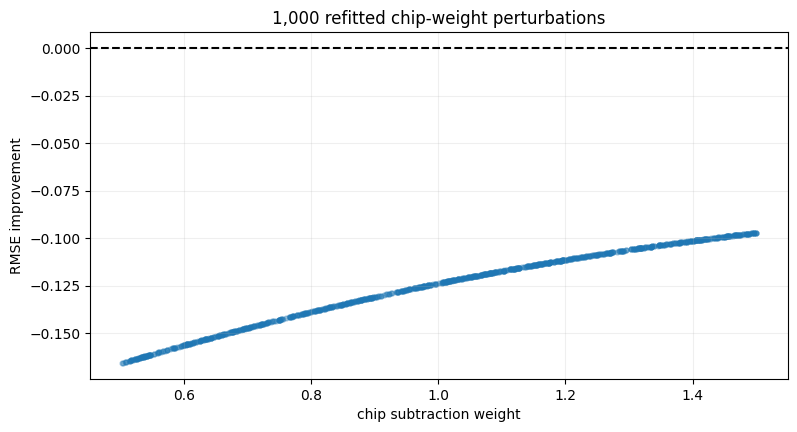

In [31]:
fig,ax=plt.subplots(figsize=(9,4.5));ax.scatter(weights.chip_subtraction_weight,weights.delta_rmse_log_pp,s=12,alpha=.35);ax.axhline(0,color='black',ls='--');ax.set(title='1,000 refitted chip-weight perturbations',xlabel='chip subtraction weight',ylabel='RMSE improvement');ax.grid(alpha=.2);plt.show()

In [32]:
abl=pd.read_csv(ROOT/'results/ablations.csv');display(abl)
loyo=pd.read_csv(ROOT/'results/leave_one_year_out.csv');display(loyo)

,model,n,rmse
0,no_chip_control,117,11.192984
1,no_manufacturing_control,117,10.197348
2,network_level_only,117,11.564820
3,base_full,117,11.471551


,excluded_year,n,delta_rmse
0,2016,114,-0.122480
1,2017,105,-0.190819
2,2018,105,0.074600
3,2019,105,-0.105490
4,2020,105,-0.233651
5,2021,105,-0.158263
6,2022,105,-0.139216
7,2023,105,-0.109344
8,2024,105,-0.131940
9,2025,105,-0.129085


## 11. Regime Sensitivity

The only positive incremental improvement occurs in the 2020–2021 period; pre-2020 and post-2021 are negative. These descriptive partitions share overlapping YoY labels and do not establish independent significance. Lag/horizon variations are reported with their own sample counts; **6- and 12-month** horizons fail the control comparison. The exceptional 2020–2021 environment may confound production cycles and weaken external validity.

In [33]:
regimes=pd.read_csv(ROOT/'results/regime_sensitivity.csv');display(regimes)
assert (regimes.loc[regimes.regime!='pandemic_2020_2021','delta_rmse']<0).all()

,regime,n,control_rmse,full_rmse,delta_rmse
0,pre_2020,39,12.399127,12.890124,-0.490998
1,pandemic_2020_2021,24,17.172869,16.935145,0.237724
2,post_2021,54,6.075149,6.136639,-0.061491


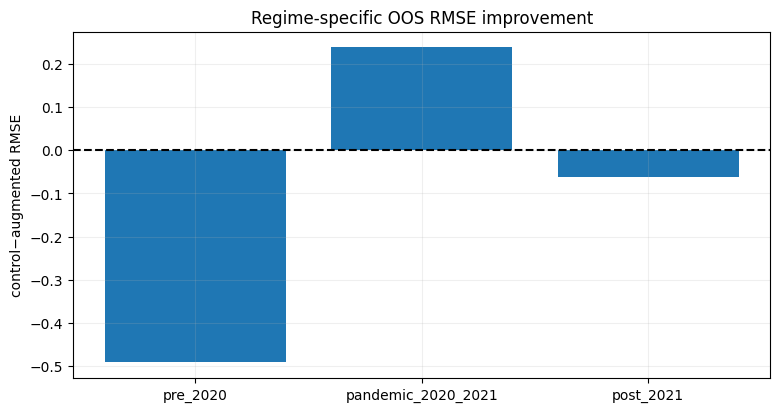

In [34]:
fig,ax=plt.subplots(figsize=(9,4.5));ax.bar(regimes.regime,regimes.delta_rmse);ax.axhline(0,color='black',ls='--');ax.set(title='Regime-specific OOS RMSE improvement',ylabel='control−augmented RMSE');ax.grid(alpha=.2);plt.show()

In [35]:
horiz=pd.read_csv(ROOT/'results/horizon_lag_robustness.csv');display(horiz)
print('Primary h=3, buffer=2:',horiz.query('horizon_months==3 and release_buffer_months==2').to_dict('records'))

,horizon_months,release_buffer_months,n,mean_rmse,control_rmse,full_rmse,delta_rmse
0,1,1,123,12.520180,6.513627,6.575508,-0.061881
1,1,2,121,12.728351,7.942241,8.032489,-0.090248
2,1,3,119,12.928357,9.771683,9.883352,-0.111669
3,1,4,117,13.148217,11.347870,11.471551,-0.123681
4,3,1,119,12.928357,9.771683,9.883352,-0.111669
5,3,2,117,13.148217,11.347870,11.471551,-0.123681
6,3,3,115,13.221847,12.120009,12.228081,-0.108072
7,3,4,113,13.181899,12.885748,13.004814,-0.119066
8,6,1,113,13.181899,12.885748,13.004814,-0.119066
9,6,2,111,13.032650,13.507379,13.633645,-0.126266


Primary h=3, buffer=2: [{'horizon_months': 3, 'release_buffer_months': 2, 'n': 117, 'mean_rmse': 13.148216566498231, 'control_rmse': 11.347869784400707, 'full_rmse': 11.471550516881154, 'delta_rmse': -0.1236807324804463}]


## 12. Bias Audit & Verdict

**Bias register:** fixed revised source observations ≠ historical PIT; temporal overlap and shared sector cycles complicate inference; selecting this factor after other repository studies creates multiple-testing risk; U.S. production is not global issuer revenue; no historical company universe or total returns means survivorship, benchmark and transaction costs are untestable. **Verdict:** H2 fails against macro control and especially AR; H3 fails regime/weight tests; H1 is a weak descriptive mechanism rather than causal evidence. A negative macro-factor result is a valid falsification, **not** proof that all electronics demand indicators lack predictive value.

In [36]:
bias=pd.DataFrame([['Release revisions','UNRESOLVED','2026-revised values may leak future revisions'],['Target overlap','PARTIALLY MITIGATED','purged training, moving-block resampling'],['Industry selection','UNRESOLVED','many prior studies and tested hypotheses'],['Firm survivorship','NOT TESTED','no historical issuer universe'],['Trading costs','NOT APPLICABLE','no return strategy or transactions'],['Independent fundamental outcomes','NOT TESTED','only G17 output']],columns=['risk','status','implication']);display(bias)

,risk,status,implication
0,Release revisions,UNRESOLVED,2026-revised values may leak future revisions
1,Target overlap,PARTIALLY MITIGATED,"purged training, moving-block resampling"
2,Industry selection,UNRESOLVED,many prior studies and tested hypotheses
3,Firm survivorship,NOT TESTED,no historical issuer universe
4,Trading costs,NOT APPLICABLE,no return strategy or transactions
5,Independent fundamental outcomes,NOT TESTED,only G17 output


In [37]:
assert s.loc[s.model=='full_network_balance','rmse_log_pp'].iloc[0]>s.loc[s.model=='macro_control','rmse_log_pp'].iloc[0]
assert s.loc[s.model=='full_network_balance','rmse_log_pp'].iloc[0]>s.loc[s.model=='ar_ridge','rmse_log_pp'].iloc[0]
print('VERDICT: NEGATIVE retrospective macro-factor falsification; NOT PIT; NOT EQUITY ALPHA')

VERDICT: NEGATIVE retrospective macro-factor falsification; NOT PIT; NOT EQUITY ALPHA


## 13. Reproduction

From a fresh checkout: `pip install -r requirements.txt`; `OPENBLAS_NUM_THREADS=1 python run_analysis.py`; `OPENBLAS_NUM_THREADS=1 python -m pytest -q tests`; `OPENBLAS_NUM_THREADS=1 jupyter nbconvert --to notebook --execute --inplace research.ipynb --ExecutePreprocessor.timeout=900`; from repo root `python scripts/validate_studies.py`. The Monte Carlo draws are deterministic with fixed seeds, but numerical/plot bytes can vary across dependency versions. The structural CI gate does not verify economic validity. This notebook reads saved Monte Carlo draws after re-running primary OOS independently.

In [38]:
saved=pd.read_csv(ROOT/'results/walk_forward_oos.csv',parse_dates=['date','target_month','latest_input_month']);assert len(saved)==len(o)
for col in ['y','macro_control','full_network_balance','ar_ridge']:
    assert np.allclose(saved[col],o[col],atol=1e-10,rtol=1e-10)
print('PASS primary notebook OOS predictions match persisted analysis',len(o),'origins')

PASS primary notebook OOS predictions match persisted analysis 117 origins


In [39]:
artifacts=[ROOT/'results/metrics.json',ROOT/'results/scorecard.csv',ROOT/'results/block_placebo_1000.csv',ROOT/'results/paired_block_bootstrap_2000.csv',ROOT/'results/exposure_perturbation_1000.csv']
assert all(p.exists() and p.stat().st_size>0 for p in artifacts)
print('PASS persisted computed tables:',[(p.name,p.stat().st_size) for p in artifacts])

PASS persisted computed tables: [('metrics.json', 2068), ('scorecard.csv', 562), ('block_placebo_1000.csv', 24250), ('paired_block_bootstrap_2000.csv', 49951), ('exposure_perturbation_1000.csv', 43534)]


In [40]:
figures=sorted((ROOT/'figures').glob('*.png'));print('Saved computed figures:',len(figures));assert len(figures)>=3

Saved computed figures: 11


## 14. Next-Stage Protocol

Rebuild original release-vintage observations (Fed archives, ALFRED), then lock an untouched future holdout and repeat with release-verified inputs. Add time-stamped orders, server shipments and capex with predeclared feature selection; collect contemporaneous company segment revenue and filing dates (including delisted issuers). Validate revenue/EPS before security returns. Only if both stages survive should a sector-neutral, dividend-adjusted total-return portfolio be tested with trading costs, capacity and false-discovery adjustment. No such evidence is claimed here.

In [41]:
next_stage=pd.DataFrame([['1','ALFRED/FRASER vintage extraction','historical release timestamps and revision deltas'],['2','Prospective macro holdout','pre-registered features and untouched forecast period'],['3','Corporate filings','dated segment exposures and sales/EPS'],['4','Investable alpha','historical universe, total returns, costs, multiple-testing']],columns=['stage','task','acceptance criterion']);display(next_stage)

,stage,task,acceptance criterion
0,1,ALFRED/FRASER vintage extraction,historical release timestamps and revision deltas
1,2,Prospective macro holdout,pre-registered features and untouched forecast...
2,3,Corporate filings,dated segment exposures and sales/EPS
3,4,Investable alpha,"historical universe, total returns, costs, mul..."


## 15. Sources & Artifacts

**Primary:** Federal Reserve G.17 2026-10-16 release, FRED series `IPG3341S`, `IPG3342S`, `IPG3344S`, `IPMAN`; Census 2017 NAICS definitions; Dell 2025 10-K (2025-03-25), HP 2025 10-K (2025-12-10), Cisco 2025 annual report. **Inherited frozen source:** semiconductor study CSV Git blob `3d111120b93de0a5eb153d794772225f5dd1a6c4`. Full URLs, dates, observed ranges, grade A/B/C, revision limitations and issuer mapping are stored in `data/source_register.csv` and `data/exposure_map.csv`. Derived panel, OOS tables, 1,000 block reorders, 2,000 paired bootstrap draws, 1,000 weight refits, regime/horizon/ablation tables and eleven figures are persisted. **No PIT series, corporate fundamentals or stock returns**.

In [42]:
display(register[['source_id','grade','original_url','revision_or_vintage']])
print('Data and results root:',ROOT)

,source_id,grade,original_url,revision_or_vintage
0,FED_G17,A,https://www.federalreserve.gov/releases/g17/20...,October 2026 fixed revised snapshot; historica...
1,IPG3341S,A,https://fred.stlouisfed.org/series/IPG3341S,Latest revised as of October 2026; individual ...
2,IPG3342S,A,https://fred.stlouisfed.org/series/IPG3342S,Latest revised as of October 2026; individual ...
3,IPG3344S,A,https://fred.stlouisfed.org/series/IPG3344S,Latest revised as of October 2026; individual ...
4,IPMAN,A,https://fred.stlouisfed.org/series/IPMAN,Latest revised as of October 2026; individual ...
5,SOURCE_COPY,B,https://github.com/HyeonbinJung/Signals-to-Alp...,Exact inherited Git blob SHA 3d111120b93de0a5e...
6,NAICS_3341,A,https://www.census.gov/naics/2017NAICS/2017_De...,2017 classification definitions
7,DELL_2025,A,https://www.sec.gov/Archives/edgar/data/157199...,2025 filing; historical exposure mapping UNKNOWN
8,HPQ_2025,A,https://www.sec.gov/Archives/edgar/data/47217/...,2025 filing; historical exposure mapping UNKNOWN
9,CISCO_2025,A,https://www.cisco.com/c/en/us/about/annual-rep...,2025 report; historic exposure mapping UNKNOWN


Data and results root: /mnt/data/s2a_run11/Network-Demand-Balance-to-Computer-Hardware-U.S.-Computer-Peripherals


In [43]:
print('Final summary:', {'n_raw':len(raw),'n_oos':len(o),'control_rmse':round(rmse(o.y,o.macro_control),4),'augmented_rmse':round(rmse(o.y,o.full_network_balance),4),'gain':round(gain,4),'bootstrap_CI':ci.tolist(),'block_tail_exploratory':round(tail,4)})

Final summary: {'n_raw': 189, 'n_oos': 117, 'control_rmse': 11.3479, 'augmented_rmse': 11.4716, 'gain': -0.1237, 'bootstrap_CI': [-0.6418424169265807, 0.15201196858935986], 'block_tail_exploratory': np.float64(0.4096)}
